In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr

rankings_raw = pd.read_csv("cutting_rankings.csv")
scores_raw = pd.read_csv("cutting_scores.csv")

REGION_FILTER = "West"
TYPE_FILTER = "Longsword"
EXCLUDED_TIERS = ["Womens", "Women's", "U18"]
RATING_DATE = None

USE_EVENT_RECENCY = True
RECENCY_HALF_LIFE_YEARS = 3.0
USE_ACTIVE_INACTIVITY_DECAY = False
USE_MASTER_INACTIVITY_DECAY = False
ACTIVE_WINDOW_YEARS = 2.0
ACTIVE_DECAY_RATE = 0.10
MASTER_REVIEW_WINDOW_YEARS = 4.0
MASTER_DECAY_RATE = 0.05

TIER1_CAREER_WEIGHT = 0.70
TIER1_LAST3_WEIGHT = 0.30
TIER1_PERFORMANCE_MULTIPLIER = 30.0
TIER1_GOLD_BONUS = 5.0
TIER1_MEDAL_BONUS = 2.0
TIER2_COMPONENT_CAP = 4.0
TIER3_COMPONENT_CAP = 1.0
CONFIDENCE_EVENTS = 5

MANUAL_STATUS_OVERRIDES = {
    "Julian_Schuetze": "No Longer Competing Due to Injury"
}

def clean(x):
    return str(x).strip().replace(" ", "_")

def pretty_label(x):
    return str(x).replace("_", " ")

def tier_to_level(tier):
    return {
        "Invitational": 1,
        "Advanced": 1,
        "Tier_A": 1,
        "Open": 2,
        "Tier_B": 2,
        "Beginner": 3,
        "Tier_C": 3
    }.get(clean(tier), 2)

def recency_weight(years_old):
    if pd.isna(years_old):
        return 0.0
    if not USE_EVENT_RECENCY:
        return 1.0
    return float(0.5 ** (years_old / RECENCY_HALF_LIFE_YEARS))

def inactivity_weight(years_inactive, model="active"):
    if pd.isna(years_inactive):
        return 0.0
    if model == "active":
        if not USE_ACTIVE_INACTIVITY_DECAY:
            return 1.0
        return float(np.exp(-ACTIVE_DECAY_RATE * years_inactive))
    if not USE_MASTER_INACTIVITY_DECAY:
        return 1.0
    capped_years = min(years_inactive, MASTER_REVIEW_WINDOW_YEARS)
    return float(np.exp(-MASTER_DECAY_RATE * capped_years))

def weighted_avg(values, weights):
    values = pd.Series(values)
    weights = pd.Series(weights)
    mask = values.notna() & weights.notna() & (weights > 0)
    if mask.sum() == 0:
        return np.nan
    return float(np.average(values[mask], weights=weights[mask]))

rankings_raw.columns = [c.strip() for c in rankings_raw.columns]
rankings_raw = rankings_raw.drop(columns=["Meta"], errors="ignore")
for col in ["Date", "Tournament", "Tier", "Name", "Rank", "Type", "Region"]:
    if col not in rankings_raw.columns:
        rankings_raw[col] = np.nan
for col in ["Tournament", "Tier", "Name", "Type", "Region"]:
    rankings_raw[col] = rankings_raw[col].fillna("").astype(str).str.strip()

rankings_raw["Date"] = pd.to_datetime(rankings_raw["Date"], errors="coerce")
rankings_raw["Rank"] = pd.to_numeric(rankings_raw["Rank"], errors="coerce")
rankings_raw["Tournament"] = rankings_raw["Tournament"].apply(clean)
rankings_raw["Tier"] = rankings_raw["Tier"].apply(clean)
rankings_raw["Name"] = rankings_raw["Name"].apply(clean)

excluded_tiers = [clean(t) for t in EXCLUDED_TIERS]
rankings = rankings_raw.dropna(subset=["Date", "Tournament", "Tier", "Name", "Rank"]).copy()
rankings = rankings[
    (rankings["Region"] == REGION_FILTER)
    & (rankings["Type"] == TYPE_FILTER)
    & (~rankings["Tier"].isin(excluded_tiers))
].copy()

rankings["tier_level"] = rankings["Tier"].apply(tier_to_level)
rankings["tier_event_id"] = rankings["Date"].dt.strftime("%Y-%m-%d") + " | " + rankings["Tournament"] + " | " + rankings["Tier"]
rankings["overall_event_id"] = rankings["Date"].dt.strftime("%Y-%m-%d") + " | " + rankings["Tournament"]
rankings["same_tier_field_size"] = rankings.groupby("tier_event_id")["Name"].transform("count")
rankings["same_tier_percentile"] = np.where(
    rankings["same_tier_field_size"] > 1,
    1 - ((rankings["Rank"] - 1) / (rankings["same_tier_field_size"] - 1)),
    1.0
)
rankings["same_tier_medal"] = (rankings["Rank"] <= 3).astype(int)
rankings["same_tier_gold"] = (rankings["Rank"] == 1).astype(int)
rankings["layer_sort_key"] = rankings["tier_level"] * 10000 + rankings["Rank"]
rankings["layered_rank"] = rankings.groupby("overall_event_id")["layer_sort_key"].rank(ascending=True, method="first")
rankings["layered_field_size"] = rankings.groupby("overall_event_id")["Name"].transform("count")
rankings["layered_percentile"] = np.where(
    rankings["layered_field_size"] > 1,
    1 - ((rankings["layered_rank"] - 1) / (rankings["layered_field_size"] - 1)),
    1.0
)
rankings = rankings.sort_values(["Date", "Tournament", "tier_level", "Rank"]).reset_index(drop=True)

scores_raw.columns = [c.strip() for c in scores_raw.columns]
scores_raw = scores_raw.drop(columns=["Meta"], errors="ignore")
for col in ["Date", "Tournament", "Tier", "Name", "Set", "Score", "Type", "Region"]:
    if col not in scores_raw.columns:
        scores_raw[col] = np.nan
for col in ["Tournament", "Tier", "Name", "Set", "Type", "Region"]:
    scores_raw[col] = scores_raw[col].fillna("").astype(str).str.strip()

scores_raw["Date"] = pd.to_datetime(scores_raw["Date"], errors="coerce")
scores_raw["Score"] = pd.to_numeric(scores_raw["Score"], errors="coerce")
scores_raw["Tournament"] = scores_raw["Tournament"].apply(clean)
scores_raw["Tier"] = scores_raw["Tier"].apply(clean)
scores_raw["Name"] = scores_raw["Name"].apply(clean)

scores = scores_raw.dropna(subset=["Date", "Tournament", "Tier", "Name", "Score"]).copy()
scores = scores[
    (scores["Region"] == REGION_FILTER)
    & (scores["Type"] == TYPE_FILTER)
    & (~scores["Tier"].isin(excluded_tiers))
].copy()
scores["tier_level"] = scores["Tier"].apply(tier_to_level)
scores["score_tier_event_id"] = scores["Date"].dt.strftime("%Y-%m-%d") + " | " + scores["Tournament"] + " | " + scores["Tier"]
scores["score_overall_event_id"] = scores["Date"].dt.strftime("%Y-%m-%d") + " | " + scores["Tournament"]

if RATING_DATE is None:
    RATING_DATE = rankings["Date"].max()

def summarize_cutter(name, rating_date):
    prior = rankings[
        (rankings["Name"] == name)
        & (rankings["Date"] <= rating_date)
    ].copy()

    if prior.empty:
        return None

    prior["years_old"] = (rating_date - prior["Date"]).dt.days / 365.25
    prior["recency_weight"] = prior["years_old"].apply(recency_weight)

    t1 = prior[prior["tier_level"] == 1].copy()
    t2 = prior[prior["tier_level"] == 2].copy()
    t3 = prior[prior["tier_level"] == 3].copy()

    events = prior["tier_event_id"].nunique()
    last_event = prior["Date"].max()
    years_inactive = (rating_date - last_event).days / 365.25

    t1_events = t1["tier_event_id"].nunique()
    t2_events = t2["tier_event_id"].nunique()
    t3_events = t3["tier_event_id"].nunique()

    t1_medals = int(t1["same_tier_medal"].sum())
    t2_medals = int(t2["same_tier_medal"].sum())
    t3_medals = int(t3["same_tier_medal"].sum())

    t1_golds = int(t1["same_tier_gold"].sum())
    t2_golds = int(t2["same_tier_gold"].sum())
    t3_golds = int(t3["same_tier_gold"].sum())

    t1_recent = weighted_avg(t1["same_tier_percentile"], t1["recency_weight"]) if not t1.empty else 0.0
    t2_recent = weighted_avg(t2["same_tier_percentile"], t2["recency_weight"]) if not t2.empty else 0.0
    t3_recent = weighted_avg(t3["same_tier_percentile"], t3["recency_weight"]) if not t3.empty else 0.0

    t1_last3_events = t1.sort_values("Date").tail(3)
    t1_last3 = weighted_avg(
        t1_last3_events["same_tier_percentile"],
        t1_last3_events["recency_weight"]
    ) if not t1_last3_events.empty else 0.0

    t1_form_score = (
        TIER1_CAREER_WEIGHT * t1_recent
        + TIER1_LAST3_WEIGHT * t1_last3
    )

    t1_performance_component = (
        TIER1_PERFORMANCE_MULTIPLIER * t1_form_score
    )

    t1_medal_component = (
        TIER1_GOLD_BONUS * np.log1p(t1_golds)
        + TIER1_MEDAL_BONUS * np.log1p(t1_medals)
    )

    t2_component = min(
        TIER2_COMPONENT_CAP,
        3.0 * t2_recent
        + 1.25 * np.log1p(t2_golds)
        + 0.50 * np.log1p(t2_medals)
    )

    t3_component = min(
        TIER3_COMPONENT_CAP,
        0.75 * t3_recent
        + 0.20 * np.log1p(t3_golds)
        + 0.10 * np.log1p(t3_medals)
    )

    confidence = (
        0.60
        + 0.40 * np.sqrt(min(events / CONFIDENCE_EVENTS, 1.0))
    )

    unadjusted_score = (
        t1_performance_component
        + t1_medal_component
        + t2_component
        + t3_component
    ) * confidence

    if t1_medals >= 1 or t1_events >= 3:
        status_band = 1
        status_label = "Established Tier 1"
    elif t1_events >= 1:
        status_band = 2
        status_label = "Tier 1 Experience"
    elif t2_golds >= 1 or t2_medals >= 2:
        status_band = 3
        status_label = "Tier 1 Promotion Candidate"
    else:
        status_band = 4
        status_label = "Developing / Lower Tier"

    return {
        "Name": name,
        "Events": events,
        "Tier1_Events": t1_events,
        "Tier2_Events": t2_events,
        "Tier3_Events": t3_events,
        "Tier1_Medals": t1_medals,
        "Tier2_Medals": t2_medals,
        "Tier3_Medals": t3_medals,
        "Tier1_Golds": t1_golds,
        "Tier2_Golds": t2_golds,
        "Tier3_Golds": t3_golds,
        "Tier1_Recent_Percentile": t1_recent,
        "Tier1_Last3_Percentile": t1_last3,
        "Tier1_Form_Score": t1_form_score,
        "Tier2_Recent_Percentile": t2_recent,
        "Tier3_Recent_Percentile": t3_recent,
        "Tier1_Performance_Component": t1_performance_component,
        "Tier1_Medal_Component": t1_medal_component,
        "Tier2_Capped_Component": t2_component,
        "Tier3_Capped_Component": t3_component,
        "Status_Band": status_band,
        "Status_Label": status_label,
        "Last_Event": last_event,
        "Years_Inactive": years_inactive,
        "Confidence": confidence,
        "Unadjusted_Domain_Score": unadjusted_score,
        "Active_Inactivity_Weight": inactivity_weight(
            years_inactive,
            "active"
        ),
        "Master_Inactivity_Weight": inactivity_weight(
            years_inactive,
            "master"
        )
    }

rating_rows = [
    summarize_cutter(name, RATING_DATE)
    for name in sorted(rankings["Name"].dropna().unique())
]

domain_ratings = pd.DataFrame(
    [row for row in rating_rows if row is not None]
)

domain_ratings["Active_Domain_Score"] = (
    domain_ratings["Unadjusted_Domain_Score"]
    * domain_ratings["Active_Inactivity_Weight"]
)

domain_ratings["Master_Domain_Score"] = (
    domain_ratings["Unadjusted_Domain_Score"]
    * domain_ratings["Master_Inactivity_Weight"]
)

domain_ratings["Activity_Status"] = np.where(
    domain_ratings["Years_Inactive"] <= ACTIVE_WINDOW_YEARS,
    "Active",
    "Inactive / Review"
)

domain_ratings["Activity_Status"] = (
    domain_ratings["Name"]
    .map(MANUAL_STATUS_OVERRIDES)
    .fillna(domain_ratings["Activity_Status"])
)

active_leaderboard = (
    domain_ratings[
        domain_ratings["Activity_Status"] == "Active"
    ]
    .sort_values(
        ["Status_Band", "Active_Domain_Score"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

master_tier_guidance = (
    domain_ratings
    .sort_values(
        ["Status_Band", "Master_Domain_Score"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

active_leaderboard.insert(
    0,
    "Active_Rank",
    active_leaderboard.index + 1
)

master_tier_guidance.insert(
    0,
    "Master_Rank",
    master_tier_guidance.index + 1
)

display_cols = [
    "Name",
    "Status_Label",
    "Events",
    "Tier1_Events",
    "Tier2_Events",
    "Tier1_Medals",
    "Tier1_Golds",
    "Tier2_Medals",
    "Tier2_Golds",
    "Tier1_Recent_Percentile",
    "Tier1_Last3_Percentile",
    "Tier1_Form_Score",
    "Tier1_Performance_Component",
    "Tier1_Medal_Component",
    "Tier2_Capped_Component",
    "Confidence",
    "Last_Event",
    "Years_Inactive"
]

print("RATING DATE:", RATING_DATE.date())
print("RANKING ROWS:", len(rankings))
print("UNIQUE CUTTERS:", rankings["Name"].nunique())
print("TIER EVENTS:", rankings["tier_event_id"].nunique())
print()

RATING DATE: 2026-06-06
RANKING ROWS: 1224
UNIQUE CUTTERS: 513
TIER EVENTS: 76



In [2]:
# EDA SUMMARY TABLES

print("RANKINGS DATASET")
print("Rows:", len(rankings))
print("Unique cutters:", rankings["Name"].nunique())
print("Unique tier events:", rankings["tier_event_id"].nunique())
print("Unique tournament events:", rankings["overall_event_id"].nunique())
print("Date range:", rankings["Date"].min().date(), "to", rankings["Date"].max().date())

print("\nSCORES DATASET")
print("Rows:", len(scores))
print("Unique cutters:", scores["Name"].nunique())
print("Unique score tier events:", scores["score_tier_event_id"].nunique())
print("Unique score tournament events:", scores["score_overall_event_id"].nunique())
print("Date range:", scores["Date"].min().date(), "to", scores["Date"].max().date())

print("\nTIER COUNTS, RANKINGS")
display(rankings["Tier"].value_counts().reset_index().rename(columns={"Tier": "Entry_Count", "index": "Tier"}))

print("\nTIER COUNTS, SCORES")
display(scores["Tier"].value_counts().reset_index().rename(columns={"Tier": "Score_Row_Count", "index": "Tier"}))

print("\nUNIQUE CUTTERS WITH ADVANCED / TIER 1 EXPERIENCE")
advanced_cutters = rankings[rankings["tier_level"] == 1]["Name"].nunique()
print(advanced_cutters)

print("\nUNIQUE ADVANCED / TIER 1 TOURNAMENTS")
advanced_tournaments = rankings[rankings["tier_level"] == 1][["Date", "Tournament"]].drop_duplicates().shape[0]
print(advanced_tournaments)

RANKINGS DATASET
Rows: 1224
Unique cutters: 513
Unique tier events: 76
Unique tournament events: 44
Date range: 2014-08-08 to 2026-06-06

SCORES DATASET
Rows: 2861
Unique cutters: 509
Unique score tier events: 71
Unique score tournament events: 40
Date range: 2017-08-10 to 2026-06-06

TIER COUNTS, RANKINGS


,Entry_Count,count
0,Open,630
1,Advanced,183
2,Tier_C,183
3,Tier_B,89
4,Tier_A,67
5,Beginner,57
6,Invitational,15



TIER COUNTS, SCORES


,Score_Row_Count,count
0,Open,1375
1,Advanced,634
2,Tier_C,295
3,Tier_B,190
4,Tier_A,175
5,Beginners,111
6,Invitational,81



UNIQUE CUTTERS WITH ADVANCED / TIER 1 EXPERIENCE
73

UNIQUE ADVANCED / TIER 1 TOURNAMENTS
27


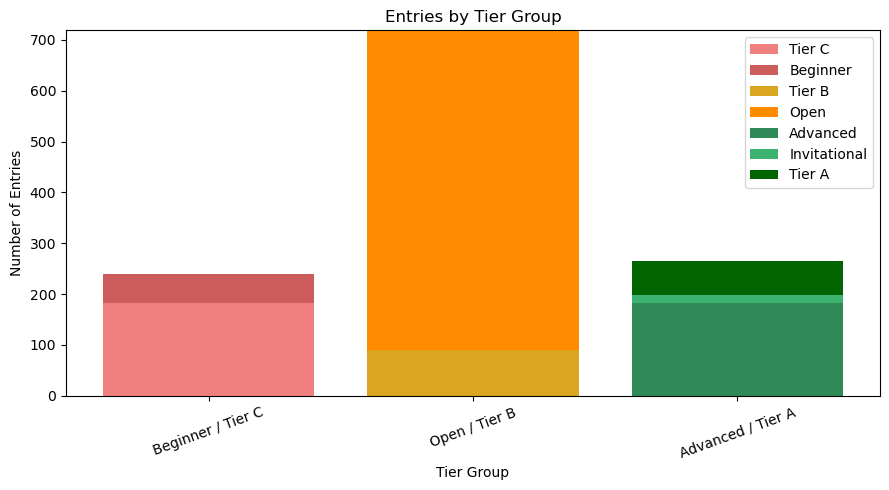

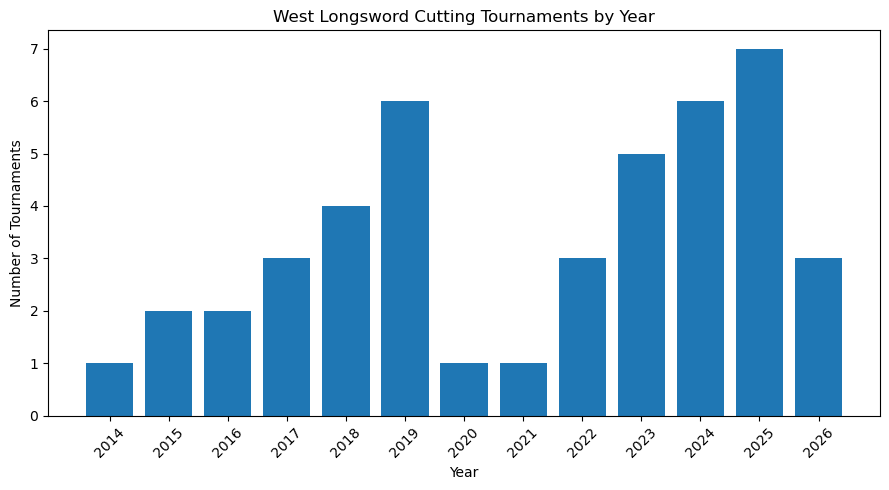

In [6]:
tier_group_map = {
    "Tier_C": "Beginner / Tier C",
    "Beginner": "Beginner / Tier C",
    "Tier_B": "Open / Tier B",
    "Open": "Open / Tier B",
    "Advanced": "Advanced / Tier A",
    "Invitational": "Advanced / Tier A",
    "Tier_A": "Advanced / Tier A"
}

tier_order = ["Tier_C", "Beginner", "Tier_B", "Open", "Advanced", "Invitational", "Tier_A"]
tier_colors = {
    "Tier_C": "lightcoral",
    "Beginner": "indianred",
    "Tier_B": "goldenrod",
    "Open": "darkorange",
    "Advanced": "seagreen",
    "Invitational": "mediumseagreen",
    "Tier_A": "darkgreen"
}

stack_data = rankings.assign(Tier_Group=rankings["Tier"].map(tier_group_map)).groupby(["Tier_Group", "Tier"]).size().unstack(fill_value=0)
stack_data = stack_data.reindex(["Beginner / Tier C", "Open / Tier B", "Advanced / Tier A"]).fillna(0)
stack_data = stack_data[[c for c in tier_order if c in stack_data.columns]]

bottom = np.zeros(len(stack_data))
plt.figure(figsize=(9, 5))
for tier in stack_data.columns:
    plt.bar(stack_data.index, stack_data[tier], bottom=bottom, label=pretty_label(tier), color=tier_colors.get(tier, "gray"))
    bottom += stack_data[tier].values

plt.title("Entries by Tier Group")
plt.xlabel("Tier Group")
plt.ylabel("Number of Entries")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

events_by_year = rankings[["Date", "overall_event_id"]].drop_duplicates().copy()
events_by_year["Year"] = events_by_year["Date"].dt.year
events_by_year = events_by_year.groupby("Year").size().reset_index(name="Tournament_Count")

plt.figure(figsize=(9, 5))
plt.bar(events_by_year["Year"].astype(str), events_by_year["Tournament_Count"])
plt.title("West Longsword Cutting Tournaments by Year")
plt.xlabel("Year")
plt.ylabel("Number of Tournaments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [3]:
# COLUMN GUIDE / DATA DICTIONARY

column_guide = pd.DataFrame([
    ["Date", "Date of the cutting event."],
    ["Tournament", "Tournament or event name."],
    ["Tier", "Competitive division, such as Advanced, Open, Beginner, Tier_A, Tier_B, or Tier_C."],
    ["Name", "Competitor name, standardized with underscores."],
    ["Rank", "Final placement within that event tier."],
    ["Type", "Weapon/event type; filtered to Longsword."],
    ["Region", "Event region; filtered to West."],
    ["tier_level", "Numeric tier grouping: 1 = Advanced/Tier A, 2 = Open/Tier B, 3 = Beginner/Tier C."],
    ["tier_event_id", "Unique event-tier identifier using Date, Tournament, and Tier."],
    ["overall_event_id", "Tournament-level identifier using Date and Tournament."],
    ["same_tier_field_size", "Number of competitors in the same tier event."],
    ["same_tier_percentile", "Placement converted to percentile within the tier; 1.0 is first place, 0.0 is last place."],
    ["same_tier_medal", "1 if the competitor placed top 3, otherwise 0."],
    ["same_tier_gold", "1 if the competitor placed first, otherwise 0."],
    ["Score", "Individual feat score from score data."],
    ["Active_Domain_Score", "Current model score used for active leaderboard ranking."],
    ["Status_Label", "Evidence category, such as Established Tier 1 or Tier 1 Promotion Candidate."]
], columns=["Field", "Meaning"])

display(column_guide)
column_guide.to_csv("cutting_data_column_guide.csv", index=False)

,Field,Meaning
0,Date,Date of the cutting event.
1,Tournament,Tournament or event name.
2,Tier,"Competitive division, such as Advanced, Open, ..."
3,Name,"Competitor name, standardized with underscores."
4,Rank,Final placement within that event tier.
5,Type,Weapon/event type; filtered to Longsword.
6,Region,Event region; filtered to West.
7,tier_level,"Numeric tier grouping: 1 = Advanced/Tier A, 2 ..."
8,tier_event_id,"Unique event-tier identifier using Date, Tourn..."
9,overall_event_id,Tournament-level identifier using Date and Tou...


ACTIVE LEADERBOARD


,Active_Rank,Name,Status_Label,Events,Tier1_Events,Tier2_Events,Tier1_Medals,Tier1_Golds,Tier2_Medals,Tier2_Golds,Tier1_Recent_Percentile,Tier1_Last3_Percentile,Tier1_Form_Score,Tier1_Performance_Component,Tier1_Medal_Component,Tier2_Capped_Component,Confidence,Last_Event,Years_Inactive,Active_Domain_Score
0,1,Phillip_Martin,Established Tier 1,17,14,3,12,5,1,1,0.854010,0.863094,0.856735,25.702053,14.088696,2.943361,1.000000,2026-03-20,0.213552,42.734110
1,2,RJ_McKeehan,Established Tier 1,17,12,5,9,3,4,1,0.780244,0.786086,0.781997,23.459902,11.536642,3.688559,1.000000,2026-06-06,0.000000,38.685104
2,3,Dan_Cheung,Established Tier 1,13,6,6,4,2,2,2,0.783383,0.735152,0.768913,23.067402,8.711937,4.000000,1.000000,2026-03-20,0.213552,36.265826
3,4,Caleb_DeWolf,Established Tier 1,7,4,1,2,2,1,1,0.813025,0.756694,0.796125,23.883764,7.690286,4.000000,1.000000,2026-06-06,0.000000,36.229979
4,5,Kevin_Spencer,Established Tier 1,15,10,5,4,1,2,1,0.741067,0.803177,0.759700,22.791003,6.684612,3.768508,1.000000,2026-06-06,0.000000,33.244123
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,71,Wesley_Ho,Developing / Lower Tier,3,0,2,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,2.104881,0.909839,2026-06-06,0.000000,2.093821
71,72,Jeremy_Liebbe,Developing / Lower Tier,1,0,1,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,2.485714,0.778885,2025-02-15,1.303217,1.936087
72,73,Scott_Wallace,Developing / Lower Tier,1,0,1,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,2.478261,0.778885,2025-08-16,0.804928,1.930281
73,74,Christopher_Soohoo,Developing / Lower Tier,3,0,2,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,1.332048,0.909839,2026-06-06,0.000000,1.924899


MASTER TIER GUIDANCE


,Master_Rank,Name,Status_Label,Events,Tier1_Events,Tier2_Events,Tier1_Medals,Tier1_Golds,Tier2_Medals,Tier2_Golds,Tier1_Recent_Percentile,Tier1_Last3_Percentile,Tier1_Form_Score,Tier1_Performance_Component,Tier1_Medal_Component,Tier2_Capped_Component,Confidence,Last_Event,Years_Inactive,Master_Domain_Score
0,1,Phillip_Martin,Established Tier 1,17,14,3,12,5,1,1,0.854010,0.863094,0.856735,25.702053,14.088696,2.943361,1.000000,2026-03-20,0.213552,42.734110
1,2,Lee_Smith,Established Tier 1,8,5,3,5,4,2,0,0.943214,0.913617,0.934335,28.030048,11.630709,2.601981,1.000000,2019-05-18,7.052704,42.262738
2,3,Julian_Schuetze,Established Tier 1,12,10,2,8,4,2,1,0.774697,0.861949,0.800873,24.026180,12.441639,3.822739,1.000000,2024-10-25,1.612594,40.290558
3,4,RJ_McKeehan,Established Tier 1,17,12,5,9,3,4,1,0.780244,0.786086,0.781997,23.459902,11.536642,3.688559,1.000000,2026-06-06,0.000000,38.685104
4,5,Jeremy_Halliday,Established Tier 1,5,4,1,3,2,1,1,0.830535,0.921204,0.857735,25.732062,8.265650,4.000000,1.000000,2023-01-14,3.392197,37.997712
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,Matthys_Kool,Developing / Lower Tier,1,0,1,0,0,1,0,0.000000,0.000000,0.000000,0.000000,0.000000,3.308112,0.778885,2019-03-28,7.192334,2.576640
96,97,Justinder_Singh,Developing / Lower Tier,3,0,3,0,0,1,0,0.000000,0.000000,0.000000,0.000000,0.000000,2.801407,0.909839,2022-02-18,4.295688,2.548829
97,98,Joshua_Barnett,Developing / Lower Tier,2,0,1,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,2.166667,0.852982,2023-07-20,2.880219,2.534919
98,99,Kyle_Edwards,Developing / Lower Tier,1,0,1,0,0,1,0,0.000000,0.000000,0.000000,0.000000,0.000000,3.231189,0.778885,2022-07-15,3.893224,2.516726


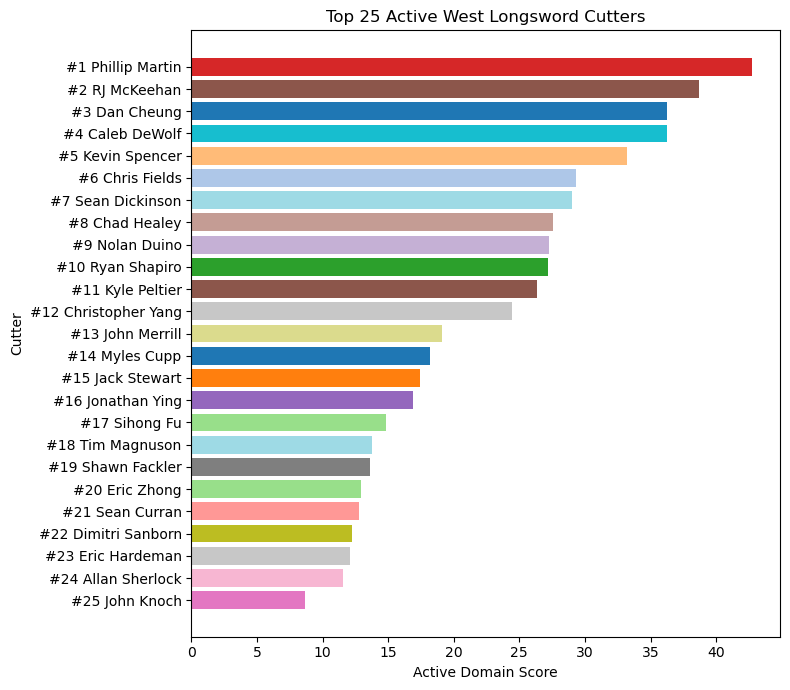

In [4]:
print("ACTIVE LEADERBOARD")
display(
    active_leaderboard[
        ["Active_Rank"]
        + display_cols
        + ["Active_Domain_Score"]
    ].head(75)
)

print("MASTER TIER GUIDANCE")
display(
    master_tier_guidance[
        ["Master_Rank"]
        + display_cols
        + ["Master_Domain_Score"]
    ].head(100)
)

active_leaderboard.to_csv(
    "active_domain_leaderboard_recent_form.csv",
    index=False
)

master_tier_guidance.to_csv(
    "master_tier_guidance_recent_form.csv",
    index=False
)

domain_ratings.to_csv(
    "domain_rating_components_recent_form.csv",
    index=False
)

top_active = active_leaderboard.head(25).copy()
top_active["Display_Name"] = (
    "#"
    + top_active["Active_Rank"].astype(int).astype(str)
    + " "
    + top_active["Name"].apply(pretty_label)
)
top_active = top_active.sort_values("Active_Domain_Score")

rng = np.random.default_rng(42)
colors = plt.cm.tab20(np.linspace(0, 1, len(top_active)))
rng.shuffle(colors)

plt.figure(figsize=(8, 7))
plt.barh(
    top_active["Display_Name"],
    top_active["Active_Domain_Score"],
    color=colors
)
plt.title("Top 25 Active West Longsword Cutters")
plt.xlabel("Active Domain Score")
plt.ylabel("Cutter")
plt.tight_layout()
plt.show()

EXPERT TOP 10


,Name,Expert_Final_Rank
0,Phillip_Martin,1
1,RJ_McKeehan,2
2,Dan_Cheung,3
3,Caleb_DeWolf,4
4,Ryan_Shapiro,5
5,Nolan_Duino,6
6,Chris_Fields,7
7,Kevin_Spencer,8
8,Chad_Healey,9
9,Jonathan_Ying,10


EXPERT TOP 10 VS ACTIVE MODEL


,Expert_Final_Rank,Active_Rank,Name,Status_Label,Events,Tier1_Events,Tier1_Medals,Tier1_Golds,Tier1_Recent_Percentile,Tier1_Last3_Percentile,Tier1_Form_Score,Tier1_Performance_Component,Tier1_Medal_Component,Tier2_Capped_Component,Active_Domain_Score
0,1,1,Phillip_Martin,Established Tier 1,17,14,12,5,0.854010,0.863094,0.856735,25.702053,14.088696,2.943361,42.734110
1,2,2,RJ_McKeehan,Established Tier 1,17,12,9,3,0.780244,0.786086,0.781997,23.459902,11.536642,3.688559,38.685104
2,3,3,Dan_Cheung,Established Tier 1,13,6,4,2,0.783383,0.735152,0.768913,23.067402,8.711937,4.000000,36.265826
3,4,4,Caleb_DeWolf,Established Tier 1,7,4,2,2,0.813025,0.756694,0.796125,23.883764,7.690286,4.000000,36.229979
4,5,10,Ryan_Shapiro,Established Tier 1,13,9,4,1,0.613609,0.426673,0.557528,16.725840,6.684612,3.786270,27.196721
5,6,9,Nolan_Duino,Established Tier 1,11,6,3,0,0.699494,0.610977,0.672939,20.188165,2.772589,3.500849,27.248309
6,7,6,Chris_Fields,Established Tier 1,15,13,4,1,0.552638,0.781933,0.621427,18.642798,6.684612,4.000000,29.327410
7,8,5,Kevin_Spencer,Established Tier 1,15,10,4,1,0.741067,0.803177,0.759700,22.791003,6.684612,3.768508,33.244123
8,9,8,Chad_Healey,Established Tier 1,3,2,2,0,0.803153,0.803153,0.803153,24.094577,2.197225,4.000000,27.560652
9,10,16,Jonathan_Ying,Established Tier 1,16,14,1,1,0.310962,0.328568,0.316244,9.487319,4.852030,2.525128,16.864477


Active top 10 overlap count: 9
Active top 10 overlap names: ['Caleb_DeWolf', 'Chad_Healey', 'Chris_Fields', 'Dan_Cheung', 'Kevin_Spencer', 'Nolan_Duino', 'Phillip_Martin', 'RJ_McKeehan', 'Ryan_Shapiro']
Spearman correlation, expert final rank vs active model rank: 0.7939393939393938


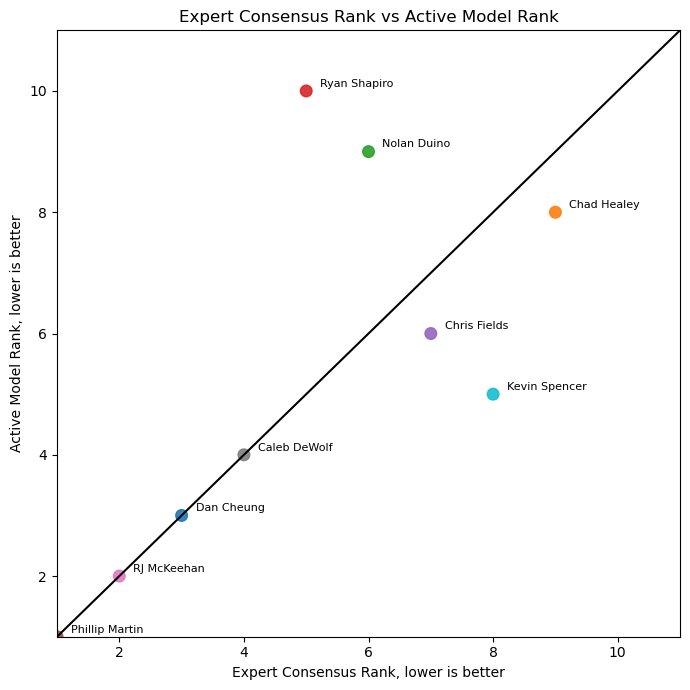

In [5]:
expert_top10 = pd.read_csv("expert_ranking_top10.csv")
expert_top10.columns = [c.strip() for c in expert_top10.columns]

if "Person" in expert_top10.columns:
    expert_top10 = expert_top10.rename(columns={"Person": "Name"})
if "final_rank" in expert_top10.columns:
    expert_top10 = expert_top10.rename(columns={"final_rank": "Expert_Final_Rank"})

expert_top10["Name"] = expert_top10["Name"].apply(clean)
expert_top10["Expert_Final_Rank"] = pd.to_numeric(expert_top10["Expert_Final_Rank"], errors="coerce")
expert_top10 = expert_top10.dropna(subset=["Name", "Expert_Final_Rank"]).sort_values("Expert_Final_Rank").reset_index(drop=True)
expert_top10["Expert_Final_Rank"] = expert_top10["Expert_Final_Rank"].astype(int)

expert_model_comparison = expert_top10.merge(active_leaderboard, on="Name", how="left")

comparison_cols = [
    "Expert_Final_Rank",
    "Active_Rank",
    "Name",
    "Status_Label",
    "Events",
    "Tier1_Events",
    "Tier1_Medals",
    "Tier1_Golds",
    "Tier1_Recent_Percentile",
    "Tier1_Last3_Percentile",
    "Tier1_Form_Score",
    "Tier1_Performance_Component",
    "Tier1_Medal_Component",
    "Tier2_Capped_Component",
    "Active_Domain_Score"
]

comparison_cols = [c for c in comparison_cols if c in expert_model_comparison.columns]

print("EXPERT TOP 10")
display(expert_top10)

print("EXPERT TOP 10 VS ACTIVE MODEL")
display(expert_model_comparison[comparison_cols])

top10_active_names = set(active_leaderboard.sort_values("Active_Rank").head(10)["Name"])
expert_names = set(expert_top10["Name"])
overlap = expert_names.intersection(top10_active_names)

rank_corr_df = expert_model_comparison.dropna(subset=["Expert_Final_Rank", "Active_Rank"]).copy()

print("Active top 10 overlap count:", len(overlap))
print("Active top 10 overlap names:", sorted(overlap))

if len(rank_corr_df) >= 3:
    print(
        "Spearman correlation, expert final rank vs active model rank:",
        spearmanr(rank_corr_df["Expert_Final_Rank"], rank_corr_df["Active_Rank"]).correlation
    )

expert_model_comparison.to_csv("expert_top10_vs_recent_form_active_model.csv", index=False)

AXIS_MAX = 15
expert_plot = rank_corr_df.copy()

rng = np.random.default_rng(42)
colors = plt.cm.tab10(np.linspace(0, 1, len(expert_plot)))
rng.shuffle(colors)

plt.figure(figsize=(7, 7))
plt.scatter(
    expert_plot["Expert_Final_Rank"],
    expert_plot["Active_Rank"],
    c=colors,
    alpha=0.9,
    s=70
)

plt.plot([1, AXIS_MAX], [1, AXIS_MAX], color="black")

for _, r in expert_plot.iterrows():
    plt.annotate(
        pretty_label(r["Name"]),
        (r["Expert_Final_Rank"], r["Active_Rank"]),
        fontsize=8,
        xytext=(10, 3),
        textcoords="offset points"
    )

plt.title("Expert Consensus Rank vs Active Model Rank")
plt.xlabel("Expert Consensus Rank, lower is better")
plt.ylabel("Active Model Rank, lower is better")
plt.xlim(1, 11)
plt.ylim(1, 11)
plt.tight_layout()
plt.show()